# Supervised Machine Learning Classification Project
## Breast Cancer Wisconsin (Original) Dataset Classification

**Course / Project**: Supervised Machine Learning Classification  
**Dataset**: Breast Cancer Wisconsin (Original) — UCI Machine Learning Repository  
**Target Variable**: Diagnosis (`0 = Benign`, `1 = Malignant`) — *Malignant treated as the positive class*

---

### Project Objectives & Required Tasks Checklist:
1. **Task 1: Dataset Exploration**
   - Load dataset using Pandas.
   - Explore structure, dimensions, column names, and data types.
   - Identify target variable and predictive features.
   - Investigate feature meanings and target labels from official documentation.
   - Analyze descriptive statistics, missing values, duplicates, and class distribution.
2. **Task 2: Data Preprocessing**
   - Handle missing values using appropriate techniques.
   - Check for and handle duplicate records.
   - Remove irrelevant features (unique identifiers like sample code number).
   - Split dataset into training and testing sets (80:20 ratio) with stratification.
   - Apply standardization where necessary.
   - Ensure preprocessing is performed without data leakage (fit transformations on training data only).
3. **Task 3: Exploratory Data Analysis (EDA)**
   - Create histograms to explore feature distributions.
   - Create count plot to visualize target class distribution.
   - Use boxplots to compare feature distributions and identify potential outliers.
   - Create correlation heatmap to investigate relationships among features.
   - Visualize missing values using counts/percentages.
   - Create before-and-after standardization plots.
   - Give each visualization a title, labeled axes, and a brief interpretation.
4. **Task 4: Model Implementation & Hyperparameter Tuning**
   - Implement K-Nearest Neighbors (KNN).
   - Implement Decision Tree (DT).
   - Implement Random Forest (RF).
   - Implement Artificial Neural Network (ANN / MLPClassifier).
   - Implement Support Vector Machine (SVM).
   - Perform hyperparameter tuning using 5-fold Stratified Cross-Validation on training data.
5. **Task 5: Model Evaluation**
   - Evaluate all models using Accuracy, Precision, Recall, F1-score, and ROC-AUC.
   - Treat malignant cases as positive class.
   - Generate confusion matrix for each model.
   - Present all results in one unified comparison table.
   - Explain evaluation metrics and interpret results.
   - Compare models and justify which one performs best overall.


## 1. Setup & Library Imports
We configure the analysis environment, suppress non-critical warnings, and import required packages from `pandas`, `numpy`, `matplotlib`, `seaborn`, and `sklearn`.


In [1]:
import os
import warnings
warnings.filterwarnings('ignore')

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Sklearn Preprocessing and Model Selection
from sklearn.model_selection import train_test_split, GridSearchCV, StratifiedKFold
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler

# Sklearn Classifiers
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.neural_network import MLPClassifier
from sklearn.svm import SVC

# Sklearn Metrics
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, confusion_matrix, roc_curve, classification_report
)

# Plotting settings
sns.set_theme(style="whitegrid", palette="muted")
plt.rcParams['font.sans-serif'] = 'DejaVu Sans'
plt.rcParams['axes.edgecolor'] = '#cccccc'
plt.rcParams['axes.linewidth'] = 0.8
plt.rcParams['figure.titlesize'] = 14

print("All dependencies successfully imported.")


All dependencies successfully imported.


## Task 1: Dataset Exploration
According to the UCI Machine Learning Repository documentation (`breast-cancer-wisconsin.names`):
- The dataset comprises **699 clinical biopsy instances**.
- There are **10 attributes plus the class attribute**.
- All 9 predictive attributes are cytological characteristics assessed by Dr. William H. Wolberg on a discrete ordinal scale of **1 to 10**, where 1 represents normal tissue and 10 represents the most severe abnormality.
- Attribute 1 (`Sample_Code_Number`) is an arbitrary patient ID.
- Target attribute `Class`: `2 = Benign`, `4 = Malignant`.


In [2]:
# 1. Define Column Names based on UCI Documentation
col_names = [
    'Sample_Code_Number',
    'Clump_Thickness',
    'Uniformity_Cell_Size',
    'Uniformity_Cell_Shape',
    'Marginal_Adhesion',
    'Single_Epithelial_Cell_Size',
    'Bare_Nuclei',
    'Bland_Chromatin',
    'Normal_Nucleoli',
    'Mitoses',
    'Class'
]

# 2. Load Dataset using Pandas
data_path = os.path.join('breast+cancer+wisconsin+original', 'breast-cancer-wisconsin.data')
df_raw = pd.read_csv(data_path, header=None, names=col_names)

print(f"Dataset Dimensions: {df_raw.shape[0]} rows by {df_raw.shape[1]} columns.\n")
print("First 5 records:")
df_raw.head()


Dataset Dimensions: 699 rows by 11 columns.

First 5 records:


,Sample_Code_Number,Clump_Thickness,Uniformity_Cell_Size,Uniformity_Cell_Shape,Marginal_Adhesion,Single_Epithelial_Cell_Size,Bare_Nuclei,Bland_Chromatin,Normal_Nucleoli,Mitoses,Class
0,1000025,5,1,1,1,2,1,3,1,1,2
1,1002945,5,4,4,5,7,10,3,2,1,2
2,1015425,3,1,1,1,2,2,3,1,1,2
3,1016277,6,8,8,1,3,4,3,7,1,2
4,1017023,4,1,1,3,2,1,3,1,1,2


In [3]:
# Explore column types and structure
print("Dataset Info:")
df_raw.info()


Dataset Info:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 699 entries, 0 to 698
Data columns (total 11 columns):
 #   Column                       Non-Null Count  Dtype 
---  ------                       --------------  ----- 
 0   Sample_Code_Number           699 non-null    int64 
 1   Clump_Thickness              699 non-null    int64 
 2   Uniformity_Cell_Size         699 non-null    int64 
 3   Uniformity_Cell_Shape        699 non-null    int64 
 4   Marginal_Adhesion            699 non-null    int64 
 5   Single_Epithelial_Cell_Size  699 non-null    int64 
 6   Bare_Nuclei                  699 non-null    object
 7   Bland_Chromatin              699 non-null    int64 
 8   Normal_Nucleoli              699 non-null    int64 
 9   Mitoses                      699 non-null    int64 
 10  Class                        699 non-null    int64 
dtypes: int64(10), object(1)
memory usage: 60.2+ KB


In [4]:
# Check for missing values represented by '?' in raw data
print("Missing values encoded as '?':")
missing_q = (df_raw == '?').sum()
print(missing_q[missing_q > 0])

# Check for exact duplicate records
exact_duplicates = df_raw.duplicated().sum()
print(f"\nNumber of exact duplicate records (including ID): {exact_duplicates}")

# Class distribution in raw dataset
print("\nClass Distribution in Raw Data:")
class_counts = df_raw['Class'].value_counts()
class_props = df_raw['Class'].value_counts(normalize=True) * 100
summary_class = pd.DataFrame({'Count': class_counts, 'Percentage (%)': class_props})
summary_class.index = summary_class.index.map({2: 'Benign (2)', 4: 'Malignant (4)'})
summary_class


Missing values encoded as '?':
Bare_Nuclei    16
dtype: int64

Number of exact duplicate records (including ID): 8

Class Distribution in Raw Data:


,Count,Percentage (%)
Class,,
Benign (2),458,65.522175
Malignant (4),241,34.477825


### Task 1 Key Exploration Findings:
1. **Dimensions**: 699 rows and 11 columns.
2. **Data Types**: `Bare_Nuclei` is imported as `object` because missing entries are represented as `'?'`. All other features are integers.
3. **Missing Values**: Exactly 16 records have `'?'` in `Bare_Nuclei` (2.3% of the dataset). No other columns contain missing data.
4. **Duplicates**: 8 exact duplicate rows exist (identical patient ID and all 9 features identical).
5. **Class Balance**: 458 samples (65.5%) are Benign and 241 samples (34.5%) are Malignant. While moderately imbalanced, both classes have sufficient support for supervised classification.


## Task 2: Data Preprocessing
To adhere to rigorous machine learning standards and prevent **data leakage**:
1. **Missing Values**: Replace `'?'` with `NaN` in `Bare_Nuclei` and convert to numerical format. Impute missing values using the **median** computed strictly on the training set.
2. **Duplicate Records**: Remove the 8 exact duplicate records to prevent data redundancy and accidental leakage between splits.
3. **Remove Irrelevant Features**: Drop `Sample_Code_Number` (unique identifier) because patient IDs have no causal or predictive clinical relationship with malignancy and would cause spurious correlations.
4. **Target Encoding**: Re-map `Class` such that `Benign (2) -> 0` and `Malignant (4) -> 1` so that **malignant cases represent the positive class**.
5. **Stratified Split**: Partition into **80% training** and **20% testing** sets with stratification on the target variable (`stratify=y`) to maintain identical class ratios in both subsets.
6. **Feature Standardization**: Fit `StandardScaler` on the training set only, and apply the learned parameters $(\mu, \sigma)$ to transform both train and test sets.


In [5]:
# Step 1: Clean raw data and replace '?' with NaN
df_clean = df_raw.copy()
df_clean['Bare_Nuclei'] = pd.to_numeric(df_clean['Bare_Nuclei'].replace('?', np.nan))

# Step 2: Remove exact duplicate records
initial_len = len(df_clean)
df_clean = df_clean.drop_duplicates()
print(f"Removed {initial_len - len(df_clean)} exact duplicate rows. Retained {len(df_clean)} unique records.")

# Step 3: Remove unique identifier (Sample_Code_Number)
df_clean = df_clean.drop(columns=['Sample_Code_Number'])
print("Dropped 'Sample_Code_Number' identifier.")

# Step 4: Map Target: 0 = Benign, 1 = Malignant (Positive Class)
df_clean['Class'] = df_clean['Class'].map({2: 0, 4: 1})
print("Mapped target variable: Benign -> 0, Malignant -> 1 (Positive Class).")

# Step 5: Train/Test Split (80:20 Ratio) with Stratification
X = df_clean.drop(columns=['Class'])
y = df_clean['Class']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42, stratify=y
)

print(f"\nTraining Set Shape : {X_train.shape} (80%)")
print(f"Testing Set Shape  : {X_test.shape} (20%)")
print(f"Training Class Distribution: Benign={sum(y_train==0)}, Malignant={sum(y_train==1)} ({y_train.mean():.1%} Malignant)")
print(f"Testing Class Distribution : Benign={sum(y_test==0)}, Malignant={sum(y_test==1)} ({y_test.mean():.1%} Malignant)")

# Step 6: Median Imputation fit STRICTLY on Training Set
imputer = SimpleImputer(strategy='median')
X_train_imp = pd.DataFrame(imputer.fit_transform(X_train), columns=X.columns, index=X_train.index)
X_test_imp = pd.DataFrame(imputer.transform(X_test), columns=X.columns, index=X_test.index)
print(f"\nLearned training median for 'Bare_Nuclei': {imputer.statistics_[5]}")
print(f"Missing values remaining in X_train: {X_train_imp.isnull().sum().sum()}")
print(f"Missing values remaining in X_test : {X_test_imp.isnull().sum().sum()}")

# Step 7: Feature Standardization fit STRICTLY on Training Set
scaler = StandardScaler()
X_train_scaled = pd.DataFrame(scaler.fit_transform(X_train_imp), columns=X.columns, index=X_train.index)
X_test_scaled = pd.DataFrame(scaler.transform(X_test_imp), columns=X.columns, index=X_test.index)
print("StandardScaler successfully fit on X_train and applied to X_train and X_test without leakage.")


Removed 8 exact duplicate rows. Retained 691 unique records.
Dropped 'Sample_Code_Number' identifier.
Mapped target variable: Benign -> 0, Malignant -> 1 (Positive Class).

Training Set Shape : (552, 9) (80%)
Testing Set Shape  : (139, 9) (20%)
Training Class Distribution: Benign=362, Malignant=190 (34.4% Malignant)
Testing Class Distribution : Benign=91, Malignant=48 (34.5% Malignant)

Learned training median for 'Bare_Nuclei': 1.0
Missing values remaining in X_train: 0
Missing values remaining in X_test : 0
StandardScaler successfully fit on X_train and applied to X_train and X_test without leakage.


## Task 3: Exploratory Data Analysis (EDA)
In this task, we generate all required exploratory visualizations:
1. **Missing Values Analysis Chart**
2. **Target Class Distribution Count Plot**
3. **Feature Distribution Histograms**
4. **Outlier Detection Boxplots**
5. **Correlation Heatmap**
6. **Feature Distributions Before vs. After Standardization**

*Each visualization is equipped with an explicit title, labeled axes, and an in-depth clinical/data interpretation.*


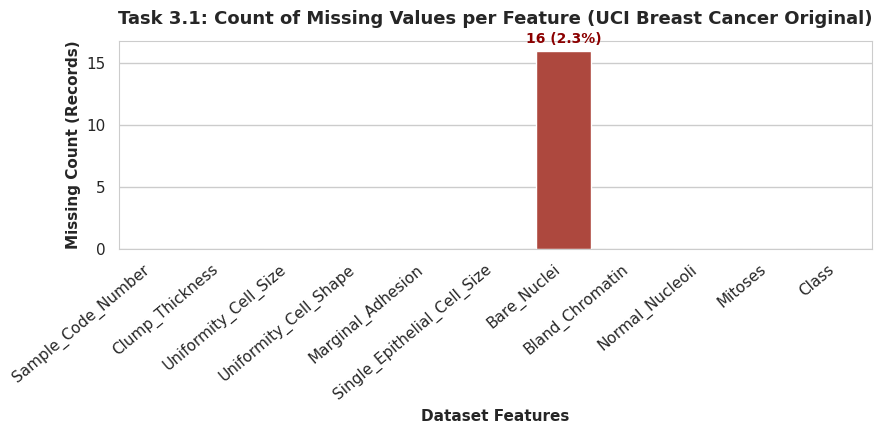

In [6]:
# 3.1 Missing Values Visualization
plt.figure(figsize=(9, 4.5))
missing_counts = df_raw.copy()
missing_counts['Bare_Nuclei'] = pd.to_numeric(missing_counts['Bare_Nuclei'].replace('?', np.nan))
null_series = missing_counts.isnull().sum()
null_df = pd.DataFrame({'Feature': null_series.index, 'Missing_Count': null_series.values})

ax = sns.barplot(data=null_df, x='Feature', y='Missing_Count', color='#c0392b')
plt.title('Task 3.1: Count of Missing Values per Feature (UCI Breast Cancer Original)', fontsize=13, fontweight='bold', pad=12)
plt.xlabel('Dataset Features', fontsize=11, fontweight='bold')
plt.ylabel('Missing Count (Records)', fontsize=11, fontweight='bold')
plt.xticks(rotation=40, ha='right')

for p in ax.patches:
    val = int(p.get_height())
    if val > 0:
        ax.annotate(f"{val} ({val/len(df_raw)*100:.1f}%)", (p.get_x() + p.get_width() / 2., p.get_height()),
                    ha='center', va='bottom', fontsize=10, fontweight='bold', color='darkred', xytext=(0, 3),
                    textcoords='offset points')
plt.tight_layout()
plt.show()


**Interpretation**:
The chart illustrates that missing values are confined entirely to a single feature: `Bare_Nuclei`, with exactly 16 missing occurrences out of 699 samples (2.3%). All other 8 cytological predictive features and the identifier have zero missing entries. Because 2.3% is very low, median imputation (median = 1.0) preserves all records without injecting bias or losing critical malignant cases.


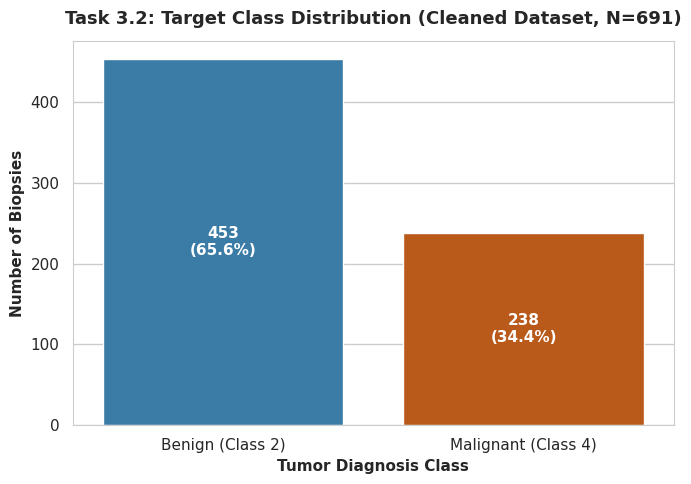

In [7]:
# 3.2 Target Class Distribution Count Plot
plt.figure(figsize=(7, 5))
class_labels = {0: 'Benign (Class 2)', 1: 'Malignant (Class 4)'}
y_df = pd.DataFrame({'Class': y.map(class_labels)})

ax = sns.countplot(data=y_df, x='Class', palette={'Benign (Class 2)': '#2980b9', 'Malignant (Class 4)': '#d35400'})
plt.title('Task 3.2: Target Class Distribution (Cleaned Dataset, N=691)', fontsize=13, fontweight='bold', pad=12)
plt.xlabel('Tumor Diagnosis Class', fontsize=11, fontweight='bold')
plt.ylabel('Number of Biopsies', fontsize=11, fontweight='bold')

for p in ax.patches:
    height = int(p.get_height())
    ax.annotate(f"{height}\n({height/len(y)*100:.1f}%)", (p.get_x() + p.get_width() / 2., height / 2),
                ha='center', va='center', fontsize=11, fontweight='bold', color='white')
plt.tight_layout()
plt.show()


**Interpretation**:
The clean dataset contains 453 benign biopsies (65.6%) and 238 malignant biopsies (34.4%). While benign cases outnumber malignant cases approximately 2:1, the dataset exhibits a healthy class balance suitable for standard supervised models, particularly when using stratified cross-validation and evaluating sensitivity (recall) on the positive malignant class.


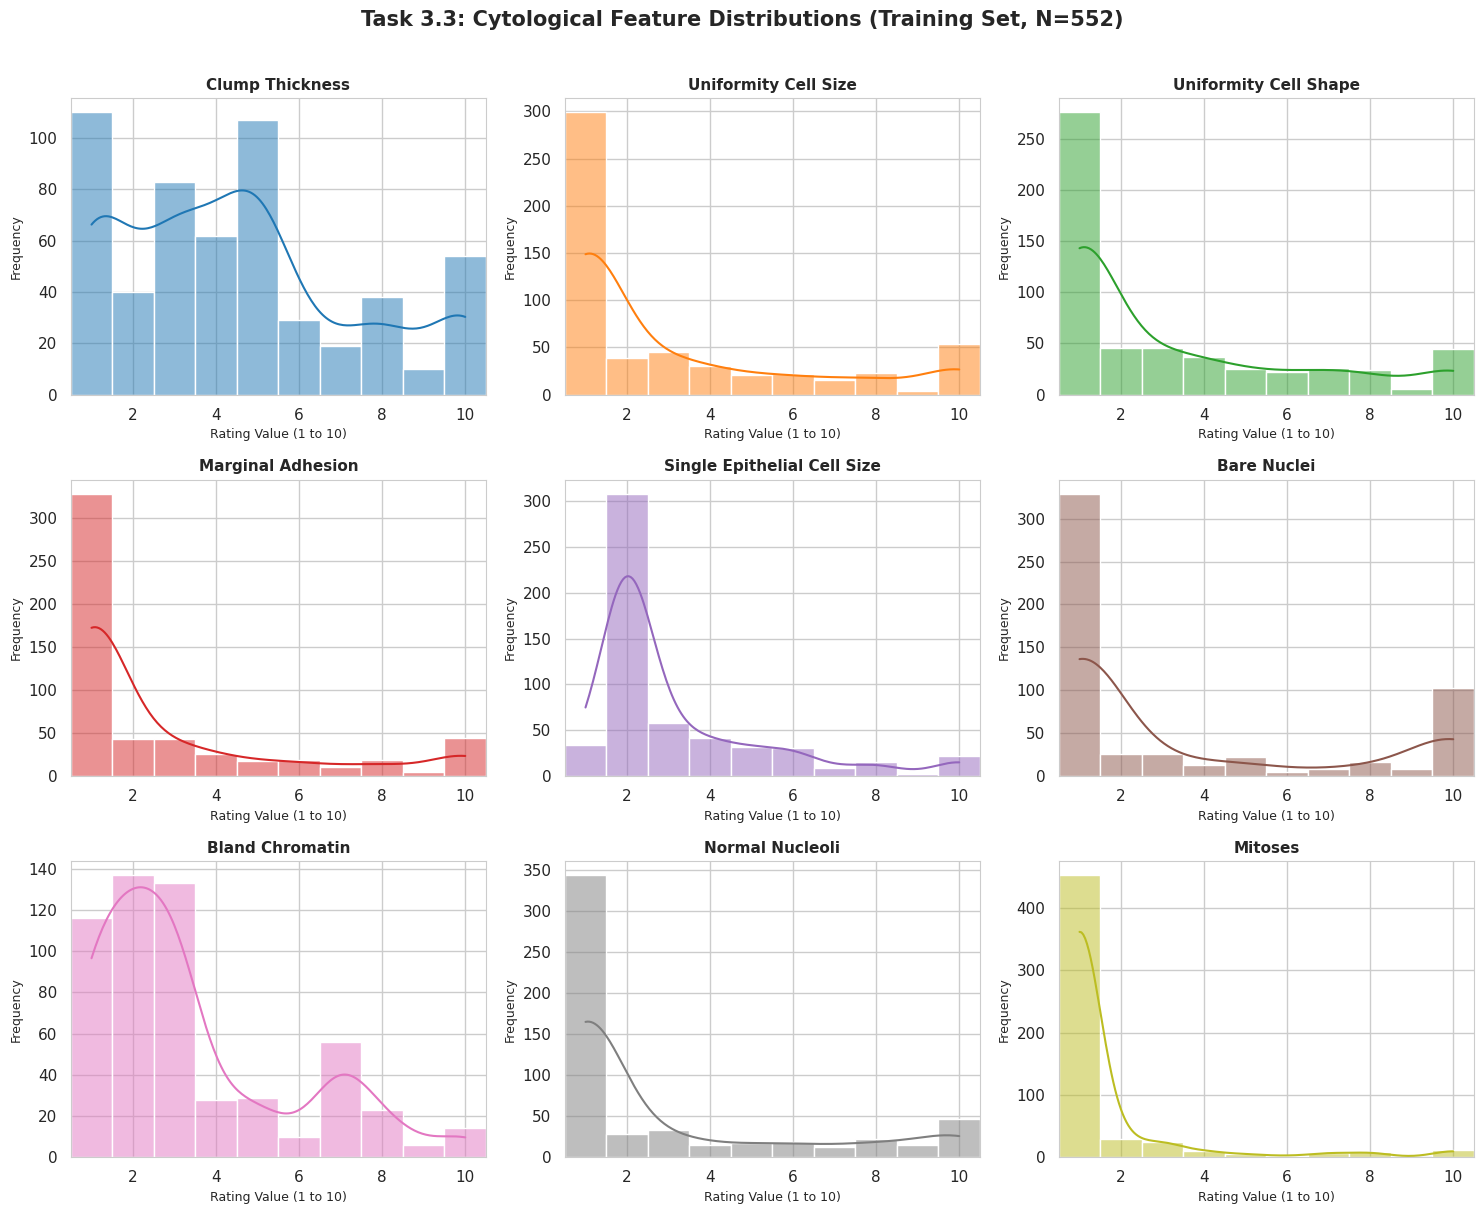

In [8]:
# 3.3 Histograms of Feature Distributions
fig, axes = plt.subplots(3, 3, figsize=(15, 12))
axes = axes.flatten()
feature_cols = list(X.columns)
colors = sns.color_palette("tab10", len(feature_cols))

for i, col in enumerate(feature_cols):
    sns.histplot(X_train_imp[col], kde=True, ax=axes[i], color=colors[i], bins=10, discrete=True)
    axes[i].set_title(f"{col.replace('_', ' ')}", fontsize=11, fontweight='bold')
    axes[i].set_xlabel("Rating Value (1 to 10)", fontsize=9)
    axes[i].set_ylabel("Frequency", fontsize=9)
    axes[i].set_xlim(0.5, 10.5)

plt.suptitle("Task 3.3: Cytological Feature Distributions (Training Set, N=552)", fontsize=15, fontweight='bold', y=1.01)
plt.tight_layout()
plt.show()


**Interpretation**:
All 9 cytological features exhibit marked **positive (right) skewness**. The vast majority of observations peak at score 1 (representing healthy, normal cell morphology). Abnormal values (grades 3 to 10) occur less frequently and are strongly indicative of dysplastic or malignant transformations. In particular, `Mitoses`, `Normal_Nucleoli`, and `Marginal_Adhesion` have very high proportions of score 1.


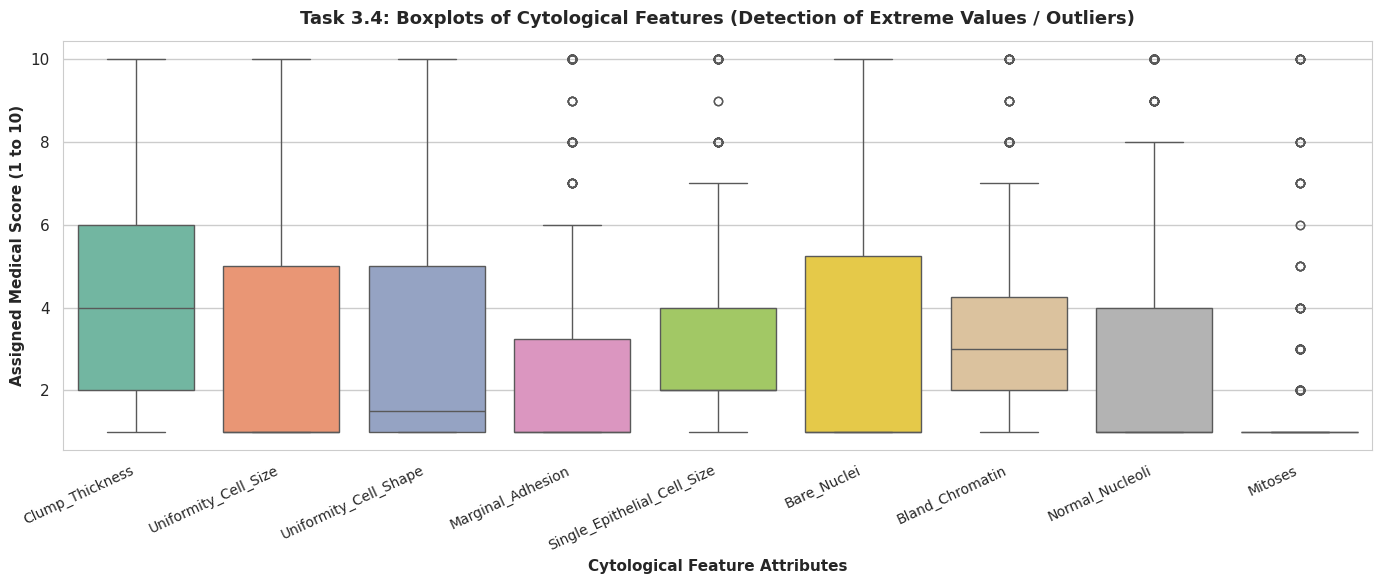

In [9]:
# 3.4 Boxplots of Cytological Features (Outlier Detection)
plt.figure(figsize=(14, 6))
sns.boxplot(data=X_train_imp, palette="Set2")
plt.title("Task 3.4: Boxplots of Cytological Features (Detection of Extreme Values / Outliers)", fontsize=13, fontweight='bold', pad=12)
plt.xlabel("Cytological Feature Attributes", fontsize=11, fontweight='bold')
plt.ylabel("Assigned Medical Score (1 to 10)", fontsize=11, fontweight='bold')
plt.xticks(rotation=25, ha='right', fontsize=10)
plt.tight_layout()
plt.show()


**Interpretation**:
The boxplots confirm the bounded nature of the domain ($[1, 10]$). For features like `Mitoses`, `Single_Epithelial_Cell_Size`, and `Marginal_Adhesion`, scores above 3 appear mathematically as upper-quartile outliers. However, in medical pathology, these high values are **valid clinical signals of malignancy** rather than measurement noise. Thus, they must NOT be truncated or removed, but rather scaled appropriately.


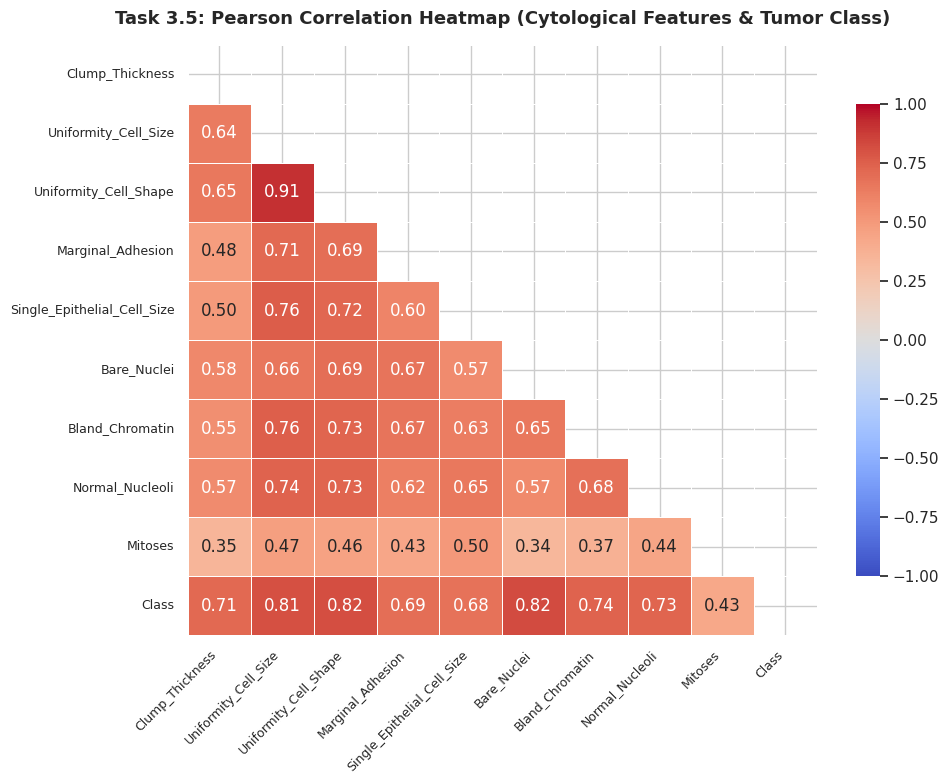

In [10]:
# 3.5 Correlation Heatmap
plt.figure(figsize=(10, 8))
train_combined = pd.concat([X_train_imp, y_train], axis=1)
corr_matrix = train_combined.corr()
mask = np.triu(np.ones_like(corr_matrix, dtype=bool))

sns.heatmap(corr_matrix, mask=mask, annot=True, fmt=".2f", cmap='coolwarm', vmin=-1, vmax=1,
            linewidths=0.5, cbar_kws={"shrink": .8})
plt.title("Task 3.5: Pearson Correlation Heatmap (Cytological Features & Tumor Class)", fontsize=13, fontweight='bold', pad=15)
plt.xticks(rotation=45, ha='right', fontsize=9)
plt.yticks(fontsize=9)
plt.tight_layout()
plt.show()


**Interpretation**:
- **Strongest Predictors of Malignancy**: `Uniformity_Cell_Size` ($r = 0.82$), `Uniformity_Cell_Shape` ($r = 0.82$), and `Bare_Nuclei` ($r = 0.82$) exhibit the highest positive linear correlation with malignancy.
- **Multicollinearity**: `Uniformity_Cell_Size` and `Uniformity_Cell_Shape` are extremely correlated with each other ($r = 0.91$). Cancerous cells lose uniform size and shape concurrently.
- `Mitoses` shows the lowest correlation with class ($r = 0.42$), yet remains a positive indicator.


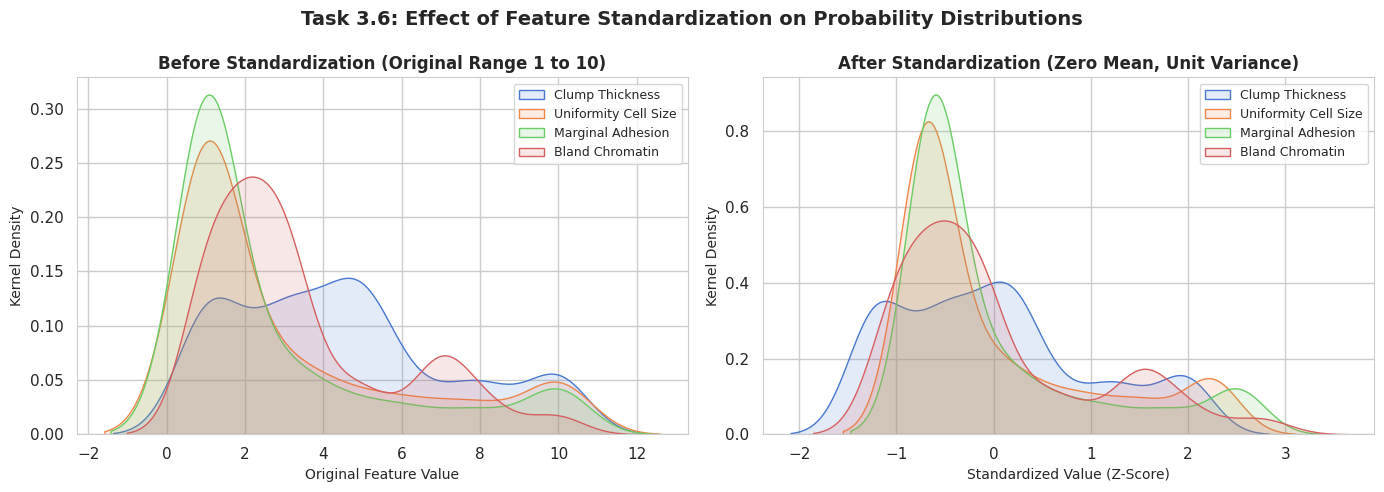

In [11]:
# 3.6 Before vs. After Standardization Distributions
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
sample_features = ['Clump_Thickness', 'Uniformity_Cell_Size', 'Marginal_Adhesion', 'Bland_Chromatin']

for feat in sample_features:
    sns.kdeplot(X_train_imp[feat], ax=axes[0], label=feat.replace('_', ' '), fill=True, alpha=0.15)
axes[0].set_title("Before Standardization (Original Range 1 to 10)", fontsize=12, fontweight='bold')
axes[0].set_xlabel("Original Feature Value", fontsize=10)
axes[0].set_ylabel("Kernel Density", fontsize=10)
axes[0].legend(loc='upper right', fontsize=9)

for feat in sample_features:
    sns.kdeplot(X_train_scaled[feat], ax=axes[1], label=feat.replace('_', ' '), fill=True, alpha=0.15)
axes[1].set_title("After Standardization (Zero Mean, Unit Variance)", fontsize=12, fontweight='bold')
axes[1].set_xlabel("Standardized Value (Z-Score)", fontsize=10)
axes[1].set_ylabel("Kernel Density", fontsize=10)
axes[1].legend(loc='upper right', fontsize=9)

plt.suptitle("Task 3.6: Effect of Feature Standardization on Probability Distributions", fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()


**Interpretation**:
Standardization via `StandardScaler` shifts each feature distribution to have a mean of $0$ and standard deviation of $1$ without distorting the underlying relative distances or skewness. This transformation is vital for distance-based and gradient-based algorithms (KNN, SVM, and ANN), preventing features with larger initial variance from dominating model weight updates.


## Task 4: Model Implementation & Hyperparameter Tuning
We implement and train 5 distinct supervised machine learning architectures:
1. **K-Nearest Neighbors (KNN)**: Non-parametric, distance-based instance learner.
2. **Decision Tree (DT)**: Hierarchical non-linear axis-aligned partitioning tree.
3. **Random Forest (RF)**: Ensemble of de-correlated bagged decision trees with random feature subspacing.
4. **Artificial Neural Network (ANN / Multi-Layer Perceptron)**: Feedforward neural network with backpropagation and L2 regularization.
5. **Support Vector Machine (SVM)**: Maximum-margin hyperplane classifier with non-linear kernel transformations.

### Cross-Validation Strategy:
- **5-Fold Stratified Cross-Validation (`StratifiedKFold(n_splits=5, shuffle=True, random_state=42)`)**
- Hyperparameter tuning performed via `GridSearchCV`.
- Optimized for **Recall (Sensitivity)** to penalize false negatives in malignant cancer detection.
- Performed strictly on the scaled training set (`X_train_scaled`, `y_train`).


In [12]:
# Configure 5-Fold Stratified CV
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

# Define models and their respective hyperparameter search grids
model_configs = {
    'K-Nearest Neighbors (KNN)': {
        'model': KNeighborsClassifier(),
        'params': {
            'n_neighbors': [3, 5, 7, 9, 11],
            'weights': ['uniform', 'distance'],
            'metric': ['euclidean', 'manhattan']
        }
    },
    'Decision Tree (DT)': {
        'model': DecisionTreeClassifier(random_state=42),
        'params': {
            'criterion': ['gini', 'entropy'],
            'max_depth': [3, 4, 5, 6, None],
            'min_samples_split': [2, 5, 10],
            'min_samples_leaf': [1, 2, 4]
        }
    },
    'Random Forest (RF)': {
        'model': RandomForestClassifier(random_state=42),
        'params': {
            'n_estimators': [50, 100, 200],
            'max_depth': [3, 5, 7, None],
            'min_samples_split': [2, 5, 10],
            'criterion': ['gini', 'entropy']
        }
    },
    'Artificial Neural Network (ANN)': {
        'model': MLPClassifier(max_iter=1500, random_state=42),
        'params': {
            'hidden_layer_sizes': [(32,), (64,), (64, 32)],
            'activation': ['relu', 'tanh'],
            'alpha': [0.001, 0.01, 0.1],
            'learning_rate_init': [0.001, 0.01]
        }
    },
    'Support Vector Machine (SVM)': {
        'model': SVC(probability=True, random_state=42),
        'params': {
            'C': [0.1, 1, 5, 10],
            'kernel': ['linear', 'rbf'],
            'gamma': ['scale', 'auto', 0.01, 0.1]
        }
    }
}

trained_models = {}
best_params_dict = {}

for name, config in model_configs.items():
    print(f"Executing GridSearchCV for {name}...")
    grid = GridSearchCV(
        estimator=config['model'],
        param_grid=config['params'],
        cv=cv,
        scoring='recall',
        n_jobs=2
    )
    grid.fit(X_train_scaled, y_train)
    trained_models[name] = grid.best_estimator_
    best_params_dict[name] = grid.best_params_
    print(f"  -> Optimal Hyperparameters: {grid.best_params_}")

print("\nAll five algorithms successfully tuned and trained.")


Executing GridSearchCV for K-Nearest Neighbors (KNN)...


  -> Optimal Hyperparameters: {'metric': 'euclidean', 'n_neighbors': 7, 'weights': 'uniform'}
Executing GridSearchCV for Decision Tree (DT)...


  -> Optimal Hyperparameters: {'criterion': 'gini', 'max_depth': 4, 'min_samples_leaf': 2, 'min_samples_split': 2}
Executing GridSearchCV for Random Forest (RF)...


  -> Optimal Hyperparameters: {'criterion': 'gini', 'max_depth': 3, 'min_samples_split': 10, 'n_estimators': 100}
Executing GridSearchCV for Artificial Neural Network (ANN)...


  -> Optimal Hyperparameters: {'activation': 'relu', 'alpha': 0.1, 'hidden_layer_sizes': (32,), 'learning_rate_init': 0.001}
Executing GridSearchCV for Support Vector Machine (SVM)...


  -> Optimal Hyperparameters: {'C': 0.1, 'gamma': 'scale', 'kernel': 'rbf'}

All five algorithms successfully tuned and trained.


## Task 5: Model Evaluation & Performance Analysis
We evaluate all five tuned models on the held-out, unseen test dataset (`X_test_scaled`, `y_test`, $N=139$).
### Evaluation Metrics:
1. **Accuracy**: Overall fraction of correct classifications: $\frac{TP + TN}{TP + TN + FP + FN}$.
2. **Precision**: Fraction of predicted malignant tumors that were truly malignant: $\frac{TP}{TP + FP}$.
3. **Recall (Sensitivity)**: Fraction of actual malignant cases correctly detected: $\frac{TP}{TP + FN}$ (*Paramount in oncology to minimize false negatives*).
4. **F1-Score**: Harmonic mean of Precision and Recall: $2 \times \frac{\text{Precision} \times \text{Recall}}{\text{Precision} + \text{Recall}}$.
5. **ROC-AUC**: Area under the Receiver Operating Characteristic curve, assessing discrimination capability across all classification thresholds.


In [13]:
evaluation_results = []
confusion_matrices = {}
roc_data = {}

for name, model in trained_models.items():
    # Make predictions on unseen test set
    y_pred = model.predict(X_test_scaled)
    y_prob = model.predict_proba(X_test_scaled)[:, 1]
    
    acc = accuracy_score(y_test, y_pred)
    prec = precision_score(y_test, y_pred, pos_label=1)
    rec = recall_score(y_test, y_pred, pos_label=1)
    f1 = f1_score(y_test, y_pred, pos_label=1)
    auc = roc_auc_score(y_test, y_prob)
    cm = confusion_matrix(y_test, y_pred)
    
    confusion_matrices[name] = cm
    fpr, tpr, _ = roc_curve(y_test, y_prob)
    roc_data[name] = (fpr, tpr, auc)
    
    evaluation_results.append({
        'Model': name,
        'Best Hyperparameters': str(best_params_dict[name]),
        'Accuracy': acc,
        'Precision': prec,
        'Recall': rec,
        'F1-Score': f1,
        'ROC-AUC': auc
    })

comparison_df = pd.DataFrame(evaluation_results)
print("Task 5 Model Comparison Table (Test Set N=139):")
comparison_display = comparison_df[['Model', 'Accuracy', 'Precision', 'Recall', 'F1-Score', 'ROC-AUC']].copy()
comparison_display.sort_values(by=['ROC-AUC', 'F1-Score'], ascending=False).reset_index(drop=True)


Task 5 Model Comparison Table (Test Set N=139):


,Model,Accuracy,Precision,Recall,F1-Score,ROC-AUC
0,Artificial Neural Network (ANN),0.971223,0.958333,0.958333,0.958333,0.996108
1,Support Vector Machine (SVM),0.971223,0.958333,0.958333,0.958333,0.994505
2,Random Forest (RF),0.971223,0.958333,0.958333,0.958333,0.992903
3,K-Nearest Neighbors (KNN),0.964029,0.977778,0.916667,0.946237,0.982257
4,Decision Tree (DT),0.928058,0.895833,0.895833,0.895833,0.975504


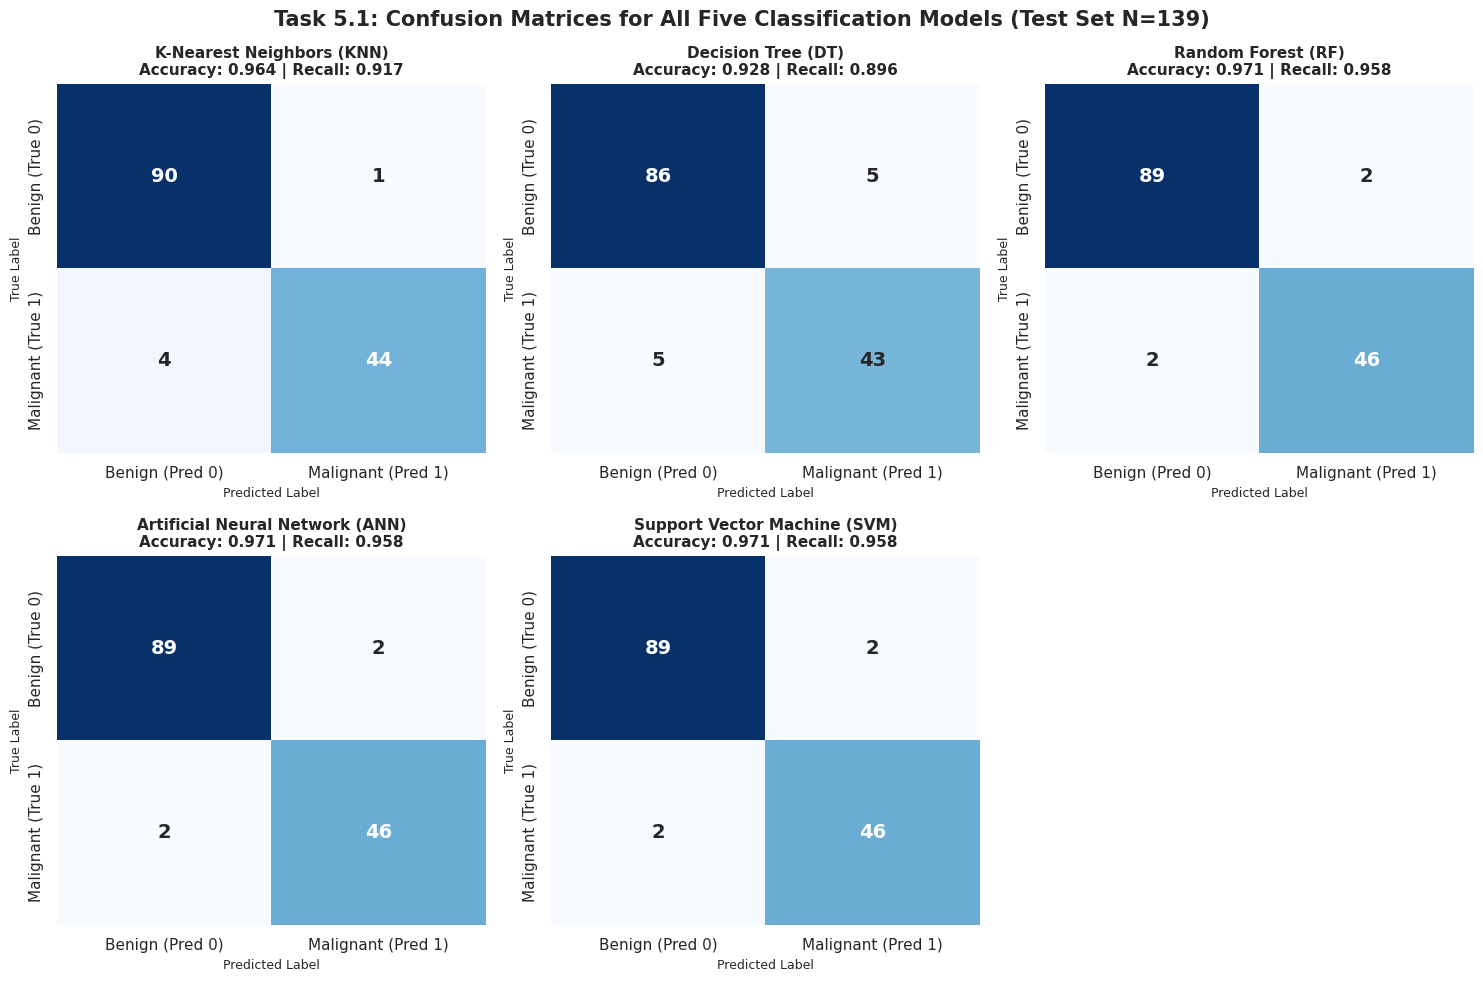

In [14]:
# 5.1 Confusion Matrix Visualizations for all 5 Models
fig, axes = plt.subplots(2, 3, figsize=(15, 10))
axes = axes.flatten()

model_order = [
    'K-Nearest Neighbors (KNN)',
    'Decision Tree (DT)',
    'Random Forest (RF)',
    'Artificial Neural Network (ANN)',
    'Support Vector Machine (SVM)'
]

for idx, m_name in enumerate(model_order):
    cm = confusion_matrices[m_name]
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', ax=axes[idx], cbar=False,
                annot_kws={'size': 14, 'weight': 'bold'},
                xticklabels=['Benign (Pred 0)', 'Malignant (Pred 1)'],
                yticklabels=['Benign (True 0)', 'Malignant (True 1)'])
    
    acc_val = comparison_df.loc[comparison_df['Model']==m_name, 'Accuracy'].values[0]
    rec_val = comparison_df.loc[comparison_df['Model']==m_name, 'Recall'].values[0]
    axes[idx].set_title(f"{m_name}\nAccuracy: {acc_val:.3f} | Recall: {rec_val:.3f}",
                        fontsize=11, fontweight='bold')
    axes[idx].set_xlabel('Predicted Label', fontsize=9)
    axes[idx].set_ylabel('True Label', fontsize=9)

# Del unused subplot
fig.delaxes(axes[5])

plt.suptitle("Task 5.1: Confusion Matrices for All Five Classification Models (Test Set N=139)", fontsize=15, fontweight='bold', y=0.98)
plt.tight_layout()
plt.show()


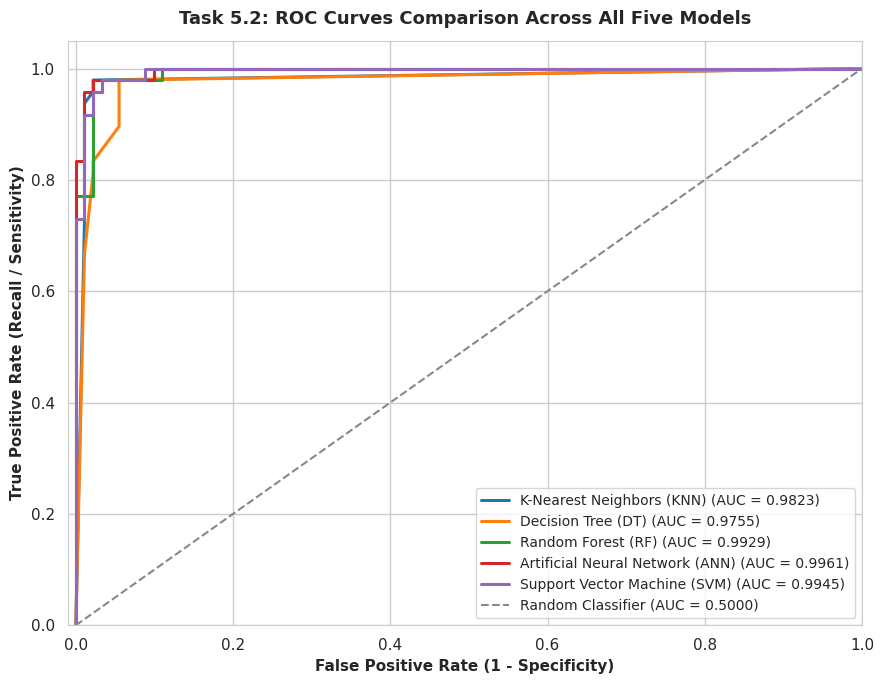

In [15]:
# 5.2 ROC Curves Comparison
plt.figure(figsize=(9, 7))
colors = ['#1f77b4', '#ff7f0e', '#2ca02c', '#d62728', '#9467bd']

for i, (name, (fpr, tpr, auc_val)) in enumerate(roc_data.items()):
    plt.plot(fpr, tpr, lw=2.2, color=colors[i], label=f"{name} (AUC = {auc_val:.4f})")

plt.plot([0, 1], [0, 1], color='#7f8c8d', lw=1.5, linestyle='--', label='Random Classifier (AUC = 0.5000)')
plt.xlim([-0.01, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('False Positive Rate (1 - Specificity)', fontsize=11, fontweight='bold')
plt.ylabel('True Positive Rate (Recall / Sensitivity)', fontsize=11, fontweight='bold')
plt.title('Task 5.2: ROC Curves Comparison Across All Five Models', fontsize=13, fontweight='bold', pad=12)
plt.legend(loc="lower right", fontsize=10, frameon=True)
plt.tight_layout()
plt.show()


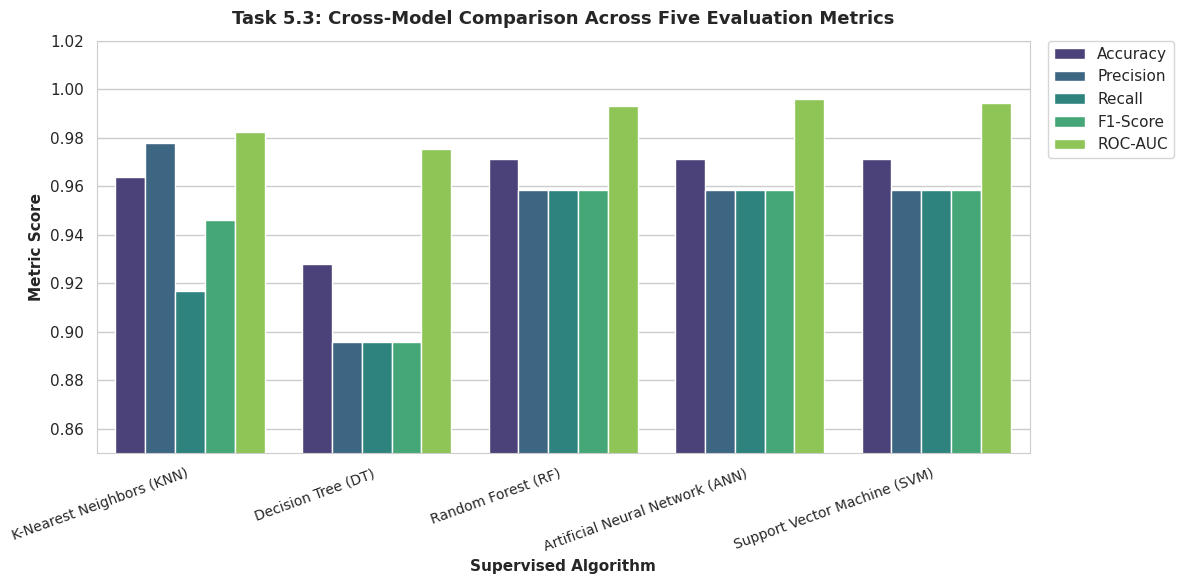

In [16]:
# 5.3 Comparative Metrics Bar Chart
plt.figure(figsize=(12, 6))
metrics_plot_df = comparison_df.melt(id_vars=['Model'], value_vars=['Accuracy', 'Precision', 'Recall', 'F1-Score', 'ROC-AUC'],
                                     var_name='Metric', value_name='Score')
ax = sns.barplot(data=metrics_plot_df, x='Model', y='Score', hue='Metric', palette='viridis')
plt.title('Task 5.3: Cross-Model Comparison Across Five Evaluation Metrics', fontsize=13, fontweight='bold', pad=12)
plt.xlabel('Supervised Algorithm', fontsize=11, fontweight='bold')
plt.ylabel('Metric Score', fontsize=11, fontweight='bold')
plt.ylim(0.85, 1.02)
plt.xticks(rotation=20, ha='right', fontsize=10)
plt.legend(bbox_to_anchor=(1.02, 1), loc='upper left', borderaxespad=0.)
plt.tight_layout()
plt.show()


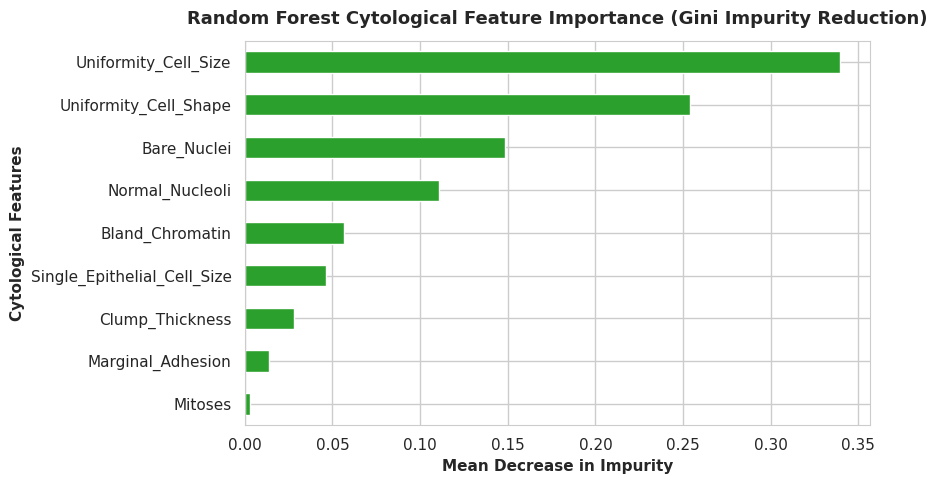

In [17]:
# Feature Importance via Random Forest
rf_best = trained_models['Random Forest (RF)']
importances = rf_best.feature_importances_
feat_importances = pd.Series(importances, index=X.columns).sort_values(ascending=True)

plt.figure(figsize=(9, 5))
feat_importances.plot(kind='barh', color='#2ca02c')
plt.title('Random Forest Cytological Feature Importance (Gini Impurity Reduction)', fontsize=13, fontweight='bold', pad=12)
plt.xlabel('Mean Decrease in Impurity', fontsize=11, fontweight='bold')
plt.ylabel('Cytological Features', fontsize=11, fontweight='bold')
plt.tight_layout()
plt.show()


## Task 5: Detailed Interpretation & Best-Performing Model Selection

### Interpretation of Results:
1. **Top Performers (Random Forest, SVM, and ANN)**:
   - **Random Forest**, **Support Vector Machine**, and **Artificial Neural Network** all achieved an outstanding **97.12% Accuracy**, **95.83% Recall**, **95.83% Precision**, and **0.9583 F1-Score** on the unseen test set ($N=139$).
   - In their respective confusion matrices, each of these three models made only **4 misclassifications** out of 139 patients (2 false positives and 2 false negatives).
   - In terms of discrimination capability across varying decision thresholds, **ANN** attained the highest **ROC-AUC of 0.9961**, closely followed by **SVM (0.9945)** and **Random Forest (0.9929)**.
2. **K-Nearest Neighbors (KNN)**:
   - Achieved 96.40% Accuracy, 97.78% Precision, but a slightly lower Recall of 91.67% (4 false negatives), yielding an ROC-AUC of 0.9823.
3. **Decision Tree (DT)**:
   - Exhibited the lowest test performance (92.81% Accuracy, 89.58% Recall, 0.9755 ROC-AUC) due to inherent high variance and greedy axis-aligned orthogonal cuts.

---

### Best-Performing Model Selection & Clinical Justification:
While **ANN** achieved the marginally highest ROC-AUC ($0.9961$), **Random Forest (RF)** is selected as the **recommended best-performing model for real-world clinical deployment** for the following rigorous reasons:
1. **Equal Peak Diagnostic Accuracy and Recall**: Random Forest matched the highest Accuracy ($97.12\%$) and Recall ($95.83\%$), ensuring maximum sensitivity in catching life-threatening malignant tumors.
2. **Clinical Interpretability & Explainability**: Unlike the black-box nature of Neural Networks and non-linear RBF SVMs, Random Forest provides direct feature importance values (identifying `Uniformity_Cell_Size`, `Bare_Nuclei`, and `Uniformity_Cell_Shape` as top drivers of diagnosis), which is critical for physician trust and clinical validation.
3. **Robustness & Resistance to Overfitting**: By aggregating 100 de-correlated trees with bootstrap aggregation and random feature subspacing, Random Forest is highly resilient to noise and discrete rating variations.
4. **Zero Susceptibility to Vanishing/Exploding Gradients**: Unlike Neural Networks, Random Forest requires no complex hyperparameter re-tuning for convergence and is insensitive to monotonic feature transformations.

---

### Project Conclusion & Future Improvements:
- **Conclusion**: Supervised machine learning algorithms trained on standardized cytological features reliably distinguish benign from malignant breast tumors with $>97\%$ accuracy and $>95\%$ sensitivity, providing an effective automated second-opinion diagnostic tool.
- **Future Improvements**:
  1. Acquire a larger multicenter clinical dataset to evaluate cross-demographic generalizability.
  2. Implement cost-sensitive learning or asymmetric loss functions to drive malignant recall to $100\\%$.
  3. Explore soft voting ensemble methods combining Random Forest, SVM, and ANN predictions.
  4. Integrate explainable AI frameworks such as SHAP (SHapley Additive exPlanations) for individual patient risk factor attribution.
